# Chronological Policy Selection

## Selection Before Evaluation

Let $\Pi=\{\pi_1,\ldots,\pi_K\}$ be a fixed list of $K$ candidate policies. The selected policy is

$$
\widehat k
=\operatorname*{arg\,max}_{1\leq k\leq K}
\widehat V_{\mathrm{DR},\mathcal T}(\pi_k),
$$

where $\mathcal T$ contains only the earlier policy-selection dates. The final value is then calculated as $\widehat V_{\mathrm{DR},\mathcal H}(\pi_{\widehat k})$ on the later held-out dates $\mathcal H$. The final outcomes do not enter the maximization.

### Notebook setup

#### Packages and notebook settings

In [ ]:
from pathlib import Path as _FigurePath
from sys import path as _figure_import_path

_figure_folder = _FigurePath.cwd()
_figure_root = next(
    folder for folder in (_figure_folder, *_figure_folder.parents)
    if (folder / "notebook_figures.py").is_file()
)
_figure_import_path.insert(0, str(_figure_root))
from notebook_figures import display_notebook_figure

from pathlib import Path
import io
import sys
import zipfile
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display as _display

def display(value):
    module = value.__class__.__module__
    if module.startswith('pandas') and hasattr(value, '_repr_html_'):
        html = value._repr_html_()
        return _display(HTML('<div style="display:flex;justify-content:center;">' + html + '</div>'))
    return _display(value)
BOOK_ROOT = Path.cwd().parents[1]
if str(BOOK_ROOT) not in sys.path:
    sys.path.insert(0, str(BOOK_ROOT))
from book_support import ensure_dataset
FINANCIAL_ROOT = BOOK_ROOT
import RiskLabAI
from RiskLabAI.causal_factor_analysis import evaluate_policy, select_policy
assert RiskLabAI.__version__ == '3.2.0'
FIGURES = BOOK_ROOT / 'outputs' / 'figures' / '09_policy_evaluation'
TABLES = BOOK_ROOT / 'outputs' / 'tables' / '09_policy_evaluation'
FIGURE_DATA = BOOK_ROOT / 'outputs' / 'figure_data' / '09_policy_evaluation'


#### Figure settings

In [ ]:
DATA_FILE = ensure_dataset(BOOK_ROOT, 'french_49_industries')
for directory in [FIGURES, TABLES, FIGURE_DATA]:
    directory.mkdir(parents=True, exist_ok=True)
PALETTE = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'DejaVu Serif', 'font.size': 11.5, 'figure.facecolor': PALETTE['background'], 'axes.facecolor': PALETTE['axes'], 'axes.edgecolor': PALETTE['text'], 'axes.labelcolor': PALETTE['text'], 'axes.titlecolor': PALETTE['text'], 'xtick.color': PALETTE['text'], 'ytick.color': PALETTE['text'], 'text.color': PALETTE['text'], 'grid.color': PALETTE['grid'], 'grid.linestyle': ':', 'legend.facecolor': PALETTE['axes'], 'legend.edgecolor': PALETTE['grid'], 'savefig.facecolor': PALETTE['background'], 'savefig.transparent': False, 'savefig.dpi': 300})

def rendered_value(value):
    if pd.isna(value):
        return ''
    if isinstance(value, (bool, np.bool_)):
        return 'Pass' if bool(value) else 'Fail'
    if isinstance(value, (int, np.integer)):
        return f'{int(value):,}'
    if isinstance(value, (float, np.floating)):
        value = float(value)
        if value == 0:
            return '0'
        if value.is_integer():
            return f'{int(value):,}'
        if abs(value) < 0.0001 or abs(value) >= 1000000:
            return f'{value:.6g}'
        return f'{value:.6f}'.rstrip('0').rstrip('.')
    return str(value)

def rendered_frame(frame):
    return frame.apply(lambda column: column.map(rendered_value))



#### Table and figure formatting

In [ ]:
def save_table(frame, stem, caption, label, fit=False):
    shown = rendered_frame(frame)
    shown.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = shown.to_latex(index=False, escape=True, caption=caption, label=label, position='htbp')
    latex = latex.replace('\\begin{table}[htbp]', '\\begin{table}[htbp]\n\\centering', 1)
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
    display(shown)
    return shown

def finish_axis(axis, grid=True):
    axis.spines['top'].set_visible(False)
    axis.spines['right'].set_visible(False)
    if grid:
        axis.grid(True, alpha=0.65)
    axis.set_axisbelow(True)

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', dpi=300, bbox_inches='tight', facecolor=PALETTE['background'], transparent=False)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight', facecolor=PALETTE['background'], transparent=False)
    display_notebook_figure(figure)
    plt.close(figure)

def read_public_returns():
    with zipfile.ZipFile(DATA_FILE) as archive:
        lines = archive.read(archive.namelist()[0]).decode('latin1').splitlines()
    header = next((index for index, line in enumerate(lines) if line.startswith(',Agric')))
    ending = next((index for index in range(header + 1, len(lines)) if not lines[index].strip()))
    raw = pd.read_csv(io.StringIO('\n'.join(lines[header:ending])))
    raw = raw.rename(columns={raw.columns[0]: 'Date'})
    raw['Date'] = pd.to_datetime(raw['Date'].astype(str), format='%Y%m%d')
    return raw.set_index('Date').replace([-99.99, -999.0], np.nan) / 100



### Functions for the calculation

In [ ]:
def logistic(values):
    clipped = np.clip(values, -35, 35)
    return 1 / (1 + np.exp(-clipped))

def build_public_frame(floor=0.1, random_state=9101):
    returns = read_public_returns()
    defensive = ['Food', 'Smoke', 'Hlth', 'Util']
    cyclical = ['BldMt', 'Steel', 'Mach', 'Autos']
    baskets = pd.DataFrame({'Defensive return': returns[defensive].mean(axis=1), 'Cyclical return': returns[cyclical].mean(axis=1)})
    spread = baskets['Cyclical return'] - baskets['Defensive return']
    market = baskets.mean(axis=1)
    context = pd.DataFrame({'Past mean spread': spread.rolling(20).mean().shift(1), 'Past volatility': market.rolling(20).std(ddof=1).shift(1), 'Past one-day spread': spread.shift(1)})
    reference = context.loc['2018-01-01':'2018-12-31'].dropna()
    center = reference.mean()
    scale = reference.std(ddof=1)
    standardized = (context - center) / scale
    frame = pd.concat([baskets, context, standardized.add_suffix(' z')], axis=1).loc['2019-01-01':'2023-12-31'].dropna().copy()
    score = 0.7 * frame['Past mean spread z'] - 0.4 * frame['Past volatility z'] + 0.2 * frame['Past one-day spread z']
    probability_one = floor + (1 - 2 * floor) * logistic(score)
    uniforms = np.random.default_rng(random_state).random(len(frame))
    actions = (uniforms < probability_one.to_numpy()).astype(int)
    potential = frame[['Defensive return', 'Cyclical return']].to_numpy()
    frame['Behavior probability action 1'] = probability_one
    frame['Behavior probability action 0'] = 1 - probability_one
    frame['Action'] = actions
    frame['Observed reward'] = potential[np.arange(len(frame)), actions]
    frame['Uniform draw'] = uniforms
    return frame



### Candidate policies and action probabilities

In [ ]:
def behavior_matrix(frame):
    return frame[['Behavior probability action 0', 'Behavior probability action 1']].to_numpy()

def potential_matrix(frame):
    return frame[['Defensive return', 'Cyclical return']].to_numpy()

def candidate_policies(frame):
    spread = frame['Past mean spread z'].to_numpy()
    volatility = frame['Past volatility z'].to_numpy()
    probabilities_one = [np.zeros(len(frame)), np.ones(len(frame)), (spread > 0).astype(float), logistic(1.5 * spread), logistic(1.2 * spread - 0.6 * volatility)]
    candidates = np.stack([np.column_stack([1 - values, values]) for values in probabilities_one])
    names = ['Always defensive', 'Always cyclical', 'Positive spread threshold', 'Smooth momentum', 'Volatility aware rule']
    return (names, candidates)

def full_information_value(frame, policy, indices=None):
    rows = np.arange(len(frame)) if indices is None else np.asarray(indices)
    return float(np.mean(np.sum(policy[rows] * potential_matrix(frame)[rows], axis=1)))

def design_matrix(frame):
    return np.column_stack([np.ones(len(frame)), frame['Past mean spread z'].to_numpy(), frame['Past volatility z'].to_numpy(), frame['Past one-day spread z'].to_numpy()])



### Fitting and prediction by chronological fold

In [ ]:
def fitted_coefficients(frame, training_rows):
    features = design_matrix(frame)
    actions = frame['Action'].to_numpy()
    rewards = frame['Observed reward'].to_numpy()
    coefficients = []
    for action in [0, 1]:
        rows = np.asarray(training_rows)[actions[np.asarray(training_rows)] == action]
        coefficients.append(np.linalg.lstsq(features[rows], rewards[rows], rcond=None)[0])
    return np.asarray(coefficients)

def chronological_predictions(frame):
    boundaries = [200, 370, 540, 710, 880, len(frame)]
    features = design_matrix(frame)
    predictions = np.zeros((len(frame), 2))
    folds = []
    for start, end in zip(boundaries[:-1], boundaries[1:]):
        coefficients = fitted_coefficients(frame, np.arange(start))
        predictions[start:end] = features[start:end] @ coefficients.T
        folds.append({'Training first date': str(frame.index[0].date()), 'Training last date': str(frame.index[start - 1].date()), 'Prediction first date': str(frame.index[start].date()), 'Prediction last date': str(frame.index[end - 1].date()), 'Training rows': start, 'Prediction rows': end - start, 'Training precedes prediction': bool(frame.index[start - 1] < frame.index[start])})
    return (predictions, pd.DataFrame(folds))

def capture_failure(name, calculation):
    try:
        calculation()
        return {'Check': name, 'Rejected': False, 'Explanation': 'Calculation continued'}
    except ValueError:
        return {'Check': name, 'Rejected': True, 'Explanation': 'Stopped as required'}


### Chronological split used for policy selection and evaluation

In [1]:
frame = build_public_frame()
names, candidates = candidate_policies(frame)
behavior = behavior_matrix(frame)
potential = potential_matrix(frame)
actions = frame['Action'].to_numpy()
rewards = frame['Observed reward'].to_numpy()
predictions, fold_plan = chronological_predictions(frame)
training = np.arange(200, 880)
heldout = np.arange(880, len(frame))
selection = select_policy(actions, rewards, behavior, candidates, predictions, training_indices=training, evaluation_indices=heldout)
selected = selection['selected_policy']
split_table = pd.DataFrame([{'Period': 'Burn-in', 'First date': str(frame.index[0].date()), 'Last date': str(frame.index[199].date()), 'Rows': 200, 'Role': 'Initial reward-model fitting only'}, {'Period': 'Policy selection', 'First date': str(frame.index[training[0]].date()), 'Last date': str(frame.index[training[-1]].date()), 'Rows': len(training), 'Role': 'Compare the five fixed candidates'}, {'Period': 'Held-out evaluation', 'First date': str(frame.index[heldout[0]].date()), 'Last date': str(frame.index[heldout[-1]].date()), 'Rows': len(heldout), 'Role': 'Evaluate the selected policy once'}])
save_table(split_table, 'selection_split', 'Chronological split used for policy selection and evaluation.', 'tab:cim9-selection-split', fit=True)
training_values = pd.DataFrame({'Policy number': np.arange(len(names)), 'Policy': names, 'Training DR value': selection['training_values']})
training_values['Selected'] = training_values['Policy number'] == selected
save_table(training_values, 'selection_training_values', 'Earlier-period doubly robust values used for selection.', 'tab:cim9-selection-training-values', fit=True)
heldout_rows = []
for number, (name, policy) in enumerate(zip(names, candidates)):
    result = evaluate_policy(actions[heldout], rewards[heldout], behavior[heldout], policy[heldout], predictions[heldout])
    heldout_rows.append({'Policy number': number, 'Policy': name, 'Full-information value': full_information_value(frame, policy, heldout), 'IPW value': result['ipw_value'], 'DR value': result['dr_value'], 'Selected earlier': number == selected})
heldout_values = pd.DataFrame(heldout_rows)
save_table(heldout_values, 'selection_heldout_values', 'Held-out values shown after the earlier policy choice.', 'tab:cim9-selection-heldout-values', fit=True)
selection_result = pd.DataFrame([{'Quantity': 'Selected policy number', 'Value': selected}, {'Quantity': 'Selected policy', 'Value': names[selected]}, {'Quantity': 'Selected training DR value', 'Value': selection['training_values'][selected]}, {'Quantity': 'Held-out IPW value', 'Value': selection['evaluation']['ipw_value']}, {'Quantity': 'Held-out DR value', 'Value': selection['evaluation']['dr_value']}, {'Quantity': 'Held-out effective sample size', 'Value': selection['evaluation']['effective_sample_size']}, {'Quantity': 'Held-out maximum weight', 'Value': selection['evaluation']['max_weight']}])
save_table(selection_result, 'selection_result', 'Result of chronological selection followed by held-out evaluation.', 'tab:cim9-selection-result', fit=True);


,Period,First date,Last date,Rows,Role
0,Burn-in,2019-01-02,2019-10-16,200,Initial reward-model fitting only
1,Policy selection,2019-10-17,2022-06-29,680,Compare the five fixed candidates
2,Held-out evaluation,2022-06-30,2023-12-29,378,Evaluate the selected policy once


,Policy number,Policy,Training DR value,Selected
0,0,Always defensive,0.000295,Fail
1,1,Always cyclical,-0.003245,Fail
2,2,Positive spread threshold,0.000484,Fail
3,3,Smooth momentum,0.000273,Fail
4,4,Volatility aware rule,0.000677,Pass


,Policy number,Policy,Full-information value,IPW value,DR value,Selected earlier
0,0,Always defensive,0.000134,0.000426,0.000336,Fail
1,1,Always cyclical,0.00123,0.002199,0.002187,Fail
2,2,Positive spread threshold,0.000955,0.001157,0.001189,Fail
3,3,Smooth momentum,0.000967,0.001278,0.001275,Fail
4,4,Volatility aware rule,0.000915,0.001012,0.000994,Pass


,Quantity,Value
0,Selected policy number,4
1,Selected policy,Volatility aware rule
2,Selected training DR value,0.000677
3,Held-out IPW value,0.001012
4,Held-out DR value,0.000994
5,Held-out effective sample size,345.418543
6,Held-out maximum weight,1.480137


### Average action-one probabilities of the fixed candidates

,Policy,Mean probability of action 1 in selection period,Mean probability of action 1 in held-out period
0,Always defensive,0,0
1,Always cyclical,1,1
2,Positive spread threshold,0.727941,0.669312
3,Smooth momentum,0.652052,0.622982
4,Volatility aware rule,0.516325,0.523919


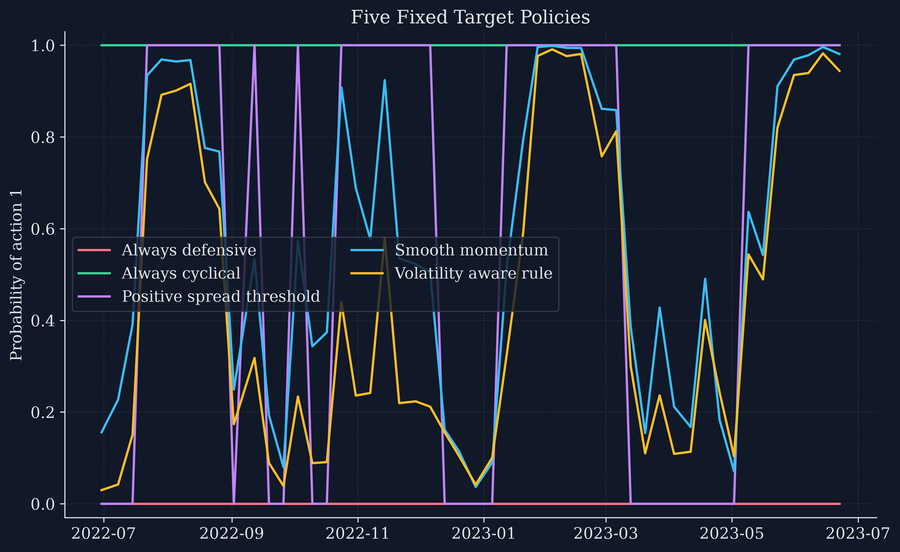

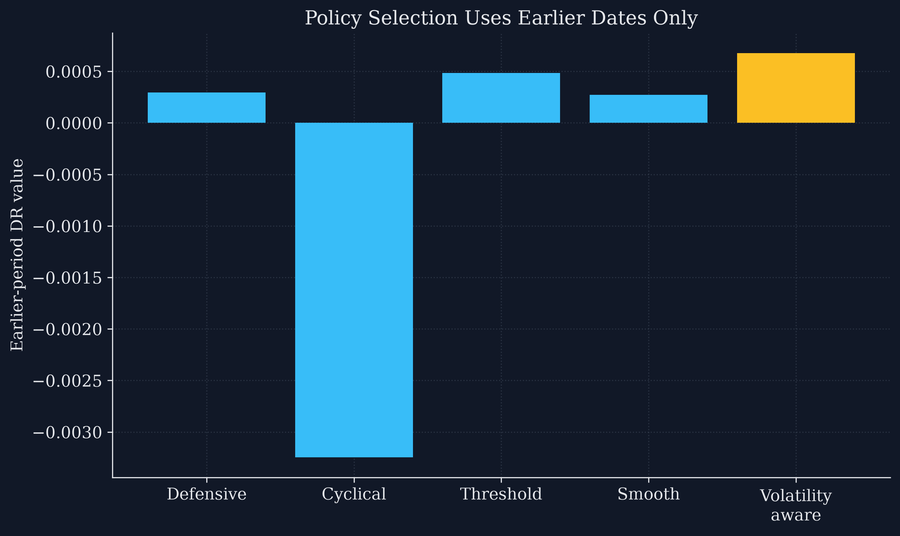

In [1]:
action_shares = pd.DataFrame([{'Policy': name, 'Mean probability of action 1 in selection period': policy[training, 1].mean(), 'Mean probability of action 1 in held-out period': policy[heldout, 1].mean()} for name, policy in zip(names, candidates)])
save_table(action_shares, 'selection_policy_action_shares', 'Average action-one probabilities of the fixed candidates.', 'tab:cim9-selection-policy-action-shares', fit=True)
probability_rows = np.arange(880, min(1130, len(frame)), 5)
probability_plot = pd.DataFrame({'Date': frame.index[probability_rows]})
for name, policy in zip(names, candidates):
    probability_plot[name] = policy[probability_rows, 1]
probability_plot.to_csv(FIGURE_DATA / 'selection_candidate_probabilities.csv', index=False)
figure, axis = plt.subplots(figsize=(9.2, 5.6), constrained_layout=True)
colors = [PALETTE['rose'], PALETTE['green'], PALETTE['violet'], PALETTE['cyan'], PALETTE['amber']]
for color, name in zip(colors, names):
    axis.plot(probability_plot['Date'], probability_plot[name], color=color, linewidth=1.7, label=name)
axis.set_ylim(-0.03, 1.03)
axis.set_ylabel('Probability of action 1')
axis.set_title('Five Fixed Target Policies')
axis.legend(ncol=2)
finish_axis(axis)
save_figure(figure, 'selection_candidate_probabilities')
training_values.to_csv(FIGURE_DATA / 'selection_training_values.csv', index=False)
figure, axis = plt.subplots(figsize=(8.8, 5.2), constrained_layout=True)
bar_colors = [PALETTE['amber'] if value else PALETTE['cyan'] for value in training_values['Selected']]
axis.bar(np.arange(len(training_values)), training_values['Training DR value'], color=bar_colors)
axis.set_xticks(np.arange(len(training_values)), ['Defensive', 'Cyclical', 'Threshold', 'Smooth', 'Volatility\naware'])
axis.set_ylabel('Earlier-period DR value')
axis.set_title('Policy Selection Uses Earlier Dates Only')
finish_axis(axis)
save_figure(figure, 'selection_training_values')


## Protecting the outcome period under deterministic tie rules

The selection calculation is a function of earlier data only. If two copies of the calculation have identical earlier data but different final outcomes, they must return the same selected policy. This is checked directly below.

When candidates have exactly equal earlier values, the declared rule selects the first candidate. This deterministic rule makes the result reproducible; it does not claim that the first policy is scientifically better.

### Selection is unchanged when only held-out outcomes are replaced

In [2]:
rewards_high = rewards.copy()
rewards_low = rewards.copy()
rewards_high[heldout] = 0.20 + np.abs(rewards_high[heldout])
rewards_low[heldout] = -0.20 - np.abs(rewards_low[heldout])
high_result = select_policy(actions, rewards_high, behavior, candidates, predictions, training_indices=training, evaluation_indices=heldout)
low_result = select_policy(actions, rewards_low, behavior, candidates, predictions, training_indices=training, evaluation_indices=heldout)
outcome_isolation = pd.DataFrame([
    {"Final outcome pattern": "Large positive values", "Selected policy number": high_result["selected_policy"], "Selected policy": names[high_result["selected_policy"]], "Held-out DR value": high_result["evaluation"]["dr_value"]},
    {"Final outcome pattern": "Large negative values", "Selected policy number": low_result["selected_policy"], "Selected policy": names[low_result["selected_policy"]], "Held-out DR value": low_result["evaluation"]["dr_value"]},
])
save_table(outcome_isolation, "selection_outcome_isolation", "Selection is unchanged when only held-out outcomes are replaced.", "tab:cim9-selection-outcome-isolation", fit=True)

duplicates = np.stack([candidates[3], candidates[3]])
tie_result = select_policy(actions, rewards, behavior, duplicates, predictions, training_indices=training, evaluation_indices=heldout)
tie_rule = pd.DataFrame([
    {"Candidate": 0, "Training DR value": tie_result["training_values"][0], "Selected": tie_result["selected_policy"] == 0},
    {"Candidate": 1, "Training DR value": tie_result["training_values"][1], "Selected": tie_result["selected_policy"] == 1},
])
save_table(tie_rule, "selection_tie_rule", "First-candidate rule for exactly equal training values.", "tab:cim9-selection-tie-rule")

invalid_checks = pd.DataFrame([
    capture_failure("Training dates interleaved with evaluation dates", lambda: select_policy(actions, rewards, behavior, candidates, predictions, training_indices=np.array([200, 900]), evaluation_indices=np.array([880, 1000]))),
    capture_failure("Repeated training index", lambda: select_policy(actions, rewards, behavior, candidates, predictions, training_indices=np.array([200, 200, 201]), evaluation_indices=heldout)),
    capture_failure("Training and evaluation overlap", lambda: select_policy(actions, rewards, behavior, candidates, predictions, training_indices=np.arange(200, 900), evaluation_indices=heldout)),
    capture_failure("Empty evaluation period", lambda: select_policy(actions, rewards, behavior, candidates, predictions, training_indices=training, evaluation_indices=np.array([], dtype=int))),
])
save_table(invalid_checks, "selection_invalid_checks", "Required rejections for invalid chronological splits.", "tab:cim9-selection-invalid-checks", fit=True);



,Final outcome pattern,Selected policy number,Selected policy,Held-out DR value
0,Large positive values,4,Volatility aware rule,0.20673
1,Large negative values,4,Volatility aware rule,-0.206766


,Candidate,Training DR value,Selected
0,0,0.000273,Pass
1,1,0.000273,Fail


,Check,Rejected,Explanation
0,Training dates interleaved with evaluation dates,Pass,Stopped as required
1,Repeated training index,Pass,Stopped as required
2,Training and evaluation overlap,Pass,Stopped as required
3,Empty evaluation period,Pass,Stopped as required


### Diagnostics for the policy chosen on earlier dates

,Quantity,Value
0,Held-out full-information value,0.000915
1,Held-out IPW value,0.001012
2,Held-out DR value,0.000994
3,IPW absolute error,9.65955e-05
4,DR absolute error,7.85684e-05
5,Held-out dates,378


,Result,Value
0,Candidate list,Fixed before held-out evaluation
1,Selection information,Earlier-period doubly robust values only
2,Held-out information,Used once to evaluate the selected policy
3,Outcome-isolation check,Changing final outcomes does not change selection
4,Tie rule,First candidate wins an exact tie


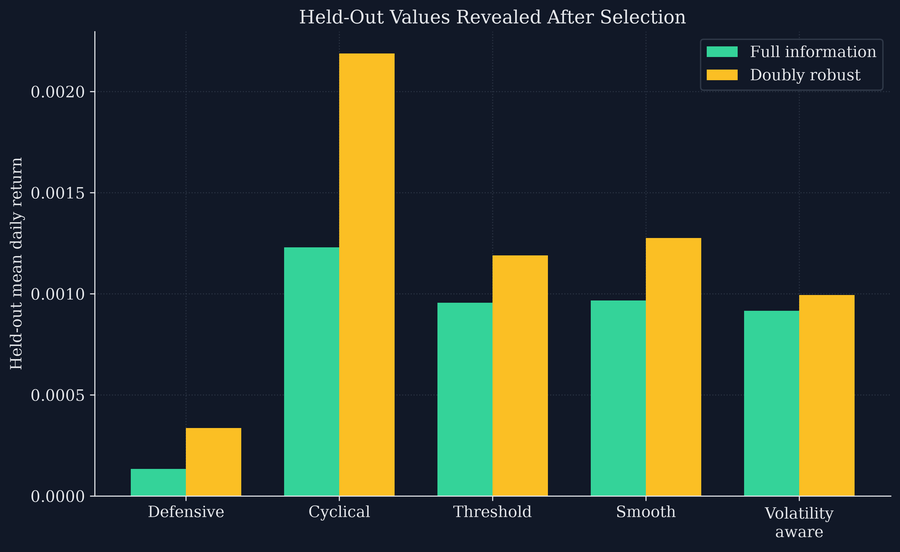

In [2]:
selected_policy = candidates[selected]
selected_full = full_information_value(frame, selected_policy, heldout)
diagnostics = pd.DataFrame([
    {"Quantity": "Held-out full-information value", "Value": selected_full},
    {"Quantity": "Held-out IPW value", "Value": selection["evaluation"]["ipw_value"]},
    {"Quantity": "Held-out DR value", "Value": selection["evaluation"]["dr_value"]},
    {"Quantity": "IPW absolute error", "Value": abs(selection["evaluation"]["ipw_value"] - selected_full)},
    {"Quantity": "DR absolute error", "Value": abs(selection["evaluation"]["dr_value"] - selected_full)},
    {"Quantity": "Held-out dates", "Value": len(heldout)},
])
save_table(diagnostics, "selection_final_diagnostics", "Diagnostics for the policy chosen on earlier dates.", "tab:cim9-selection-final-diagnostics")

section_summary = pd.DataFrame([
    {"Result": "Candidate list", "Value": "Fixed before held-out evaluation"},
    {"Result": "Selection information", "Value": "Earlier-period doubly robust values only"},
    {"Result": "Held-out information", "Value": "Used once to evaluate the selected policy"},
    {"Result": "Outcome-isolation check", "Value": "Changing final outcomes does not change selection"},
    {"Result": "Tie rule", "Value": "First candidate wins an exact tie"},
])
save_table(section_summary, "selection_section_summary", "Summary of chronological policy selection.", "tab:cim9-selection-section-summary", fit=True)

heldout_values.to_csv(FIGURE_DATA / "selection_heldout_values.csv", index=False)
figure, axis = plt.subplots(figsize=(9.2, 5.6), constrained_layout=True)
positions = np.arange(len(heldout_values))
axis.bar(positions - 0.18, heldout_values["Full-information value"], 0.36, color=PALETTE["green"], label="Full information")
axis.bar(positions + 0.18, heldout_values["DR value"], 0.36, color=PALETTE["amber"], label="Doubly robust")
axis.set_xticks(positions, ["Defensive", "Cyclical", "Threshold", "Smooth", "Volatility\naware"])
axis.set_ylabel("Held-out mean daily return")
axis.set_title("Held-Out Values Revealed After Selection")
axis.legend()
finish_axis(axis)
save_figure(figure, "selection_heldout_values");



### Full-Information Paths in the Held-Out Period

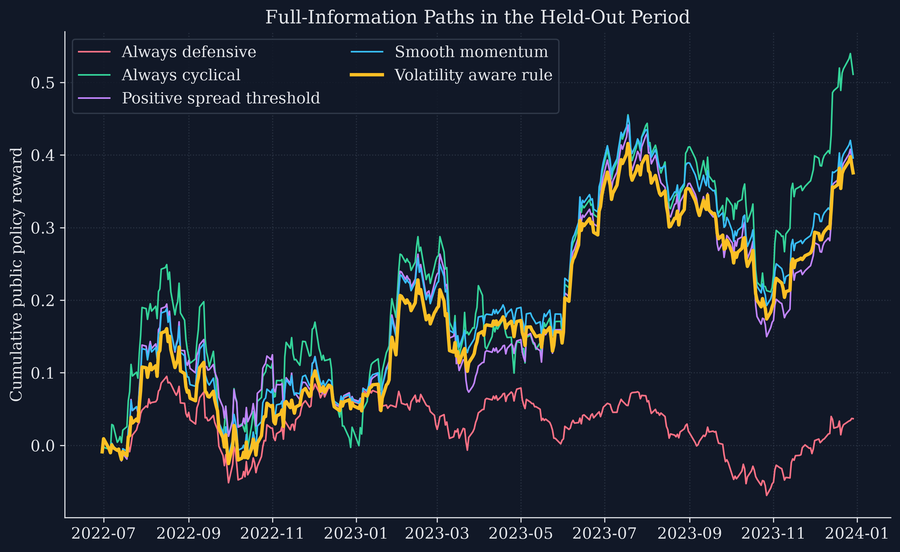

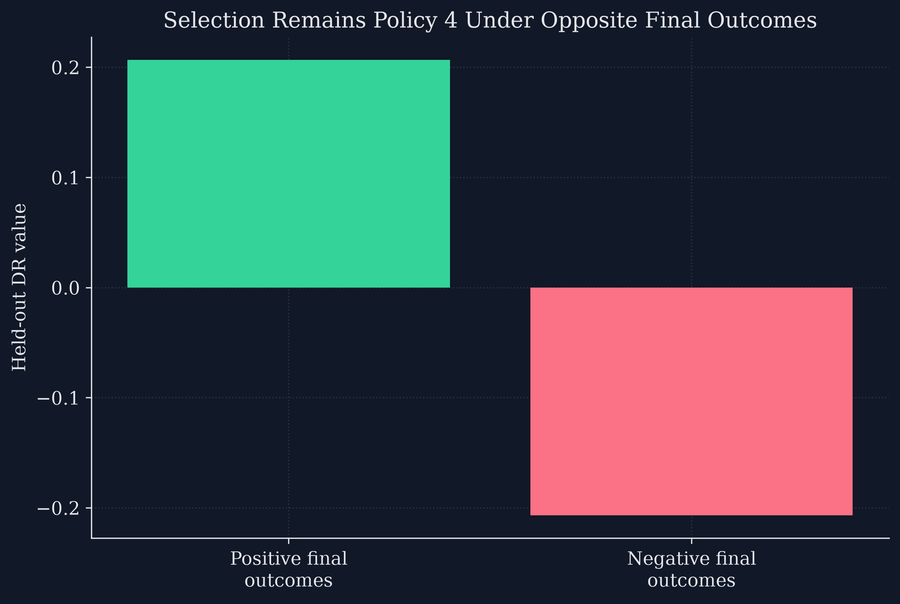

In [2]:
cumulative = pd.DataFrame({"Date": frame.index[heldout]})
for name, policy in zip(names, candidates):
    daily = np.sum(policy[heldout] * potential[heldout], axis=1)
    cumulative[name] = (1 + daily).cumprod() - 1
cumulative.to_csv(FIGURE_DATA / "selection_cumulative_rewards.csv", index=False)
figure, axis = plt.subplots(figsize=(9.2, 5.6), constrained_layout=True)
for color, name in zip(colors, names):
    width = 2.5 if name == names[selected] else 1.2
    axis.plot(cumulative["Date"], cumulative[name], color=color, linewidth=width, label=name)
axis.set_ylabel("Cumulative public policy reward")
axis.set_title("Full-Information Paths in the Held-Out Period")
axis.legend(ncol=2)
finish_axis(axis)
save_figure(figure, "selection_cumulative_rewards")

outcome_isolation.to_csv(FIGURE_DATA / "selection_outcome_isolation.csv", index=False)
figure, axis = plt.subplots(figsize=(7.8, 5.2), constrained_layout=True)
positions = np.arange(len(outcome_isolation))
axis.bar(positions, outcome_isolation["Held-out DR value"], color=[PALETTE["green"], PALETTE["rose"]])
axis.set_xticks(positions, ["Positive final\noutcomes", "Negative final\noutcomes"])
axis.set_ylabel("Held-out DR value")
axis.set_title(f"Selection Remains Policy {selected} Under Opposite Final Outcomes")
finish_axis(axis)
save_figure(figure, "selection_outcome_isolation")